## Import

In [1]:
import pandas as pd
import numpy as np
import json
import pickle

from pathlib import Path

from pykeen.pipeline import pipeline
from pykeen.triples import TriplesFactory

## Load KG TRAIN

In [2]:
KG_PATH = Path("../outputs/kg_train.tsv")

kg_df = pd.read_csv(
    KG_PATH,
    sep="\t"
)

print("KG shape:", kg_df.shape)

display(kg_df.head())

KG shape: (448000, 3)


,head,relation,tail
0,child_train_000001,has_weight,weight_1
1,child_train_000001,has_height,height_0.685714
2,child_train_000001,has_age,age_0
3,child_train_000001,has_gross_motor,gross_motor_delayed
4,child_train_000001,has_fine_motor_adaptive,fine_motor_adaptive_caution


## Validasi ulang leakage

In [3]:
assert "has_dev_status" not in kg_df["relation"].values

print("✅ dev_status tidak terdapat dalam KG.")
print("✅ KG hanya menggunakan TRAIN.")

✅ dev_status tidak terdapat dalam KG.
✅ KG hanya menggunakan TRAIN.


## Buat TriplesFactory

In [4]:
triples = kg_df[
    ["head", "relation", "tail"]
].values

tf = TriplesFactory.from_labeled_triples(
    triples
)

print("Entities :", tf.num_entities)
print("Relations:", tf.num_relations)
print("Triples  :", tf.num_triples)

Entities : 64111
Relations: 7
Triples  : 448000


## Split internal untuk evaluasi TransE

In [5]:
# Split internal berdasarkan triple untuk evaluasi TransE

training_tf, testing_tf = tf.split(
    ratios=[0.8, 0.2],
    random_state=42
)

print("KGE training triples :", training_tf.num_triples)
print("KGE testing triples  :", testing_tf.num_triples)
print("Total triples        :", tf.num_triples)

KGE training triples : 358400
KGE testing triples  : 89600
Total triples        : 448000


## Train TransE

In [6]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("⚠️ CUDA tidak tersedia. Training akan gagal jika dipaksa menggunakan cuda.")

CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


In [7]:
result = pipeline(
    training=training_tf,
    testing=testing_tf,

    model="TransE",

    model_kwargs={
        "embedding_dim": 100,
        "random_seed": 42
    },

    loss_kwargs={
        "margin": 1.0
    },

    random_seed=42,

    training_kwargs={
        "num_epochs": 100
    },

    negative_sampler="basic",  
 
    evaluation_kwargs={
        "batch_size": 256
    },

    device="cuda" if torch.cuda.is_available() else "cpu"
)

Training epochs on cuda:0:   0%|          | 0/100 [00:00<?, ?epoch/s]

Training batches on cuda:0:   0%|          | 0.00/1.40k [00:00<?, ?batch/s]

Training batches on cuda:0:   0%|          | 0.00/1.40k [00:00<?, ?batch/s]

Training batches on cuda:0:   0%|          | 0.00/1.40k [00:00<?, ?batch/s]

Training batches on cuda:0:   0%|          | 0.00/1.40k [00:00<?, ?batch/s]

Training batches on cuda:0:   0%|          | 0.00/1.40k [00:00<?, ?batch/s]

... (93 outputs left out)

Training batches on cuda:0:   0%|          | 0.00/1.40k [00:00<?, ?batch/s]

Training batches on cuda:0:   0%|          | 0.00/1.40k [00:00<?, ?batch/s]

Evaluating on cuda:0:   0%|          | 0.00/89.6k [00:00<?, ?triple/s]

INFO:pykeen.evaluation.evaluator:Evaluation took 693.67s seconds


## Ambil evaluasi MRR, Hits@3, Hits@10

In [8]:
metrics = result.metric_results

print(metrics)

In [9]:
print("===== TRANS-E EVALUATION =====")

mrr = metrics.get_metric(
    "both.realistic.inverse_harmonic_mean_rank"
)

hits3 = metrics.get_metric(
    "both.realistic.Hits@3"
)

hits10 = metrics.get_metric(
    "both.realistic.Hits@10"
)

mean_rank = metrics.get_metric(
    "both.realistic.MeanRank"
)

print("MRR      :", mrr)
print("Hits@3   :", hits3)
print("Hits@10  :", hits10)
print("MeanRank :", mean_rank)

===== TRANS-E EVALUATION =====
MRR      : 0.017048560082912445
Hits@3   : 0.01615513392857143
Hits@10  : 0.046160714285714284
MeanRank : 11420.2568359375


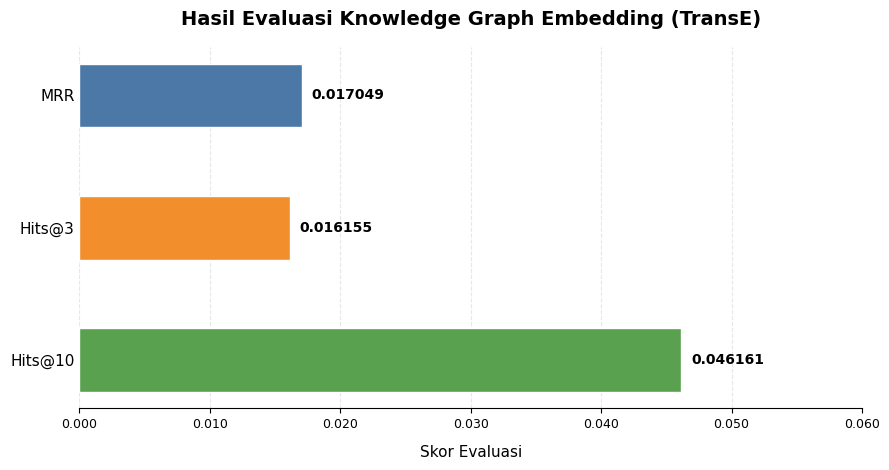

In [10]:

# Visualisasi Hasil Evaluasi Knowledge Graph Embedding (TransE)

import matplotlib.pyplot as plt
import numpy as np

# Data hasil evaluasi
metric_names = ["MRR", "Hits@3", "Hits@10"]
metric_values = [
    float(mrr),
    float(hits3),
    float(hits10)
]

# Menentukan batas sumbu berdasarkan nilai tertinggi
max_value = max(metric_values)
axis_limit = max_value * 1.30

# Membuat visualisasi
fig, ax = plt.subplots(figsize=(9, 4.8))

bars = ax.barh(
    metric_names,
    metric_values,
    height=0.48,
    color=["#4C78A8", "#F28E2B", "#59A14F"],
    edgecolor="white",
    linewidth=1
)

# Urutan metrik dari atas ke bawah
ax.invert_yaxis()

# Judul dan label
ax.set_title(
    "Hasil Evaluasi Knowledge Graph Embedding (TransE)",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.set_xlabel(
    "Skor Evaluasi",
    fontsize=11,
    labelpad=10
)

# Batas dan format sumbu X
ax.set_xlim(0, axis_limit)
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.3f}")
)

# Menampilkan nilai pada setiap batang
ax.bar_label(
    bars,
    labels=[f"{value:.6f}" for value in metric_values],
    padding=7,
    fontsize=10,
    fontweight="bold"
)

# Tampilan grid dan garis
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis="y", length=0, labelsize=11)
ax.tick_params(axis="x", labelsize=9)

fig.tight_layout()
plt.show()


## Simpan model

In [11]:
MODEL_DIR = Path("../models/transe")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "transe_model.pkl"

with open(MODEL_PATH, "wb") as f:
    pickle.dump(result, f)

print("✅ Model TransE disimpan:")
print(MODEL_PATH)

✅ Model TransE disimpan:
..\models\transe\transe_model.pkl


## Simpan metrics

In [12]:
METRIC_DIR = Path("../outputs/metrics")
METRIC_DIR.mkdir(parents=True, exist_ok=True)

transe_metrics = {
    "model": "TransE",
    "embedding_dim": 100,
    "margin": 1.0,
    "random_seed": 42,

    "kge_train_triples": int(training_tf.num_triples),
    "kge_test_triples": int(testing_tf.num_triples),

    "mrr": float(mrr),
    "hits_at_3": float(hits3),
    "hits_at_10": float(hits10),
    "mean_rank": float(mean_rank)
}

with open(
    METRIC_DIR / "transe_metrics.json",
    "w"
) as f:
    json.dump(
        transe_metrics,
        f,
        indent=4
    )

print("✅ Metrics TransE disimpan.")

✅ Metrics TransE disimpan.


## Final Checkpoint

In [13]:
print("=" * 60)
print("CHECKPOINT 5 — TRAIN TRANS-E")
print("=" * 60)

print("\nParameter:")
print("Model               : TransE")
print("Embedding dimension :", 100)
print("Margin              :", 1.0)
print("Random seed         :", 42)

print("\nData:")
print("Original KG         :", tf.num_triples)
print("KGE training triples :", training_tf.num_triples)
print("KGE evaluation       :", testing_tf.num_triples)


print("\nStatus:")
print("✅ TransE berhasil dilatih.")
print("✅ dev_status tidak digunakan.")
print("✅ TEST 20% penelitian tidak digunakan.")
print("✅ Evaluasi KGE menggunakan bagian TRAIN.")

CHECKPOINT 5 — TRAIN TRANS-E

Parameter:
Model               : TransE
Embedding dimension : 100
Margin              : 1.0
Random seed         : 42

Data:
Original KG         : 448000
KGE training triples : 358400
KGE evaluation       : 89600

Status:
✅ TransE berhasil dilatih.
✅ dev_status tidak digunakan.
✅ TEST 20% penelitian tidak digunakan.
✅ Evaluasi KGE menggunakan bagian TRAIN.
